# Honeypot standup plots

In Cursor, run this with the Python 3 kernel. It reads `sessions.csv` in this folder.
On Google Colab, the same cell asks you to upload the file.

Each row is one finished attack. Duration is `session_seconds`. The time limit is 300 seconds (the honeypot kicks the session at 5 minutes). Idle timeout is 60 seconds and is kept in these plots.

The last two plots use one point per attacker IP: the earliest attack from that IP. An IP whose first attack hit 300 seconds is left out of the final plot, not replaced by a later attack.

The box inside each violin is the median and the middle 50% of durations. The violin width shows how many attacks sit at that duration.


In [13]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

try:
    from google.colab import files
    uploaded = files.upload()
    name = next(iter(uploaded))
except ModuleNotFoundError:
    name = Path("sessions1.csv")

df = pd.read_csv(name)
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["session_seconds"] = pd.to_numeric(df["session_seconds"], errors="coerce")
df["config"] = df["config"].astype(str).str.replace(r"\.0$", "", regex=True)
df = df.dropna(subset=["session_seconds"])
df = df[df["config"].isin(["1", "2", "3", "4", "5"])].copy()

LABELS = {
    "1": "1 control",
    "2": "2 25% ascii",
    "3": "3 50% ascii",
    "4": "4 75% ascii",
    "5": "5 100% ascii",
}
ORDER = list(LABELS.values())
TIME_LIMIT = 300
TIMEOUT_REASONS = {"session timeout", "kicked at 5 minutes", "timeout"}

df["config_label"] = df["config"].map(LABELS)
df["hit_time_limit"] = (df["session_seconds"] >= TIME_LIMIT) | (
    df["reason"].fillna("").str.strip().str.lower().isin(TIMEOUT_REASONS)
)
print(f"attacks: {len(df)}")
print(f"unique ips: {df['attacker_ip'].nunique()}")
print(f"hit the 5 minute limit: {int(df['hit_time_limit'].sum())}")
df.head()


attacks: 2475
unique ips: 32
hit the 5 minute limit: 0


,timestamp,honeypot,config,attacker_ip,session_seconds,reason,commands,keystrokes,config_label,hit_time_limit
0,2026-10-28 19:52:20,hp1,3,179.43.153.2,2,attacker left,1,0,3 50% ascii,False
1,2026-10-28 19:53:42,hp1,2,179.43.153.2,2,attacker left,1,0,2 25% ascii,False
2,2026-10-28 19:55:01,hp1,3,179.43.153.2,2,attacker left,1,0,3 50% ascii,False
3,2026-10-28 19:56:21,hp1,5,179.43.153.2,2,attacker left,1,0,5 100% ascii,False
4,2026-10-28 19:57:40,hp1,4,179.43.153.2,2,attacker left,1,0,4 75% ascii,False


## Number of attacks per IP address

A few addresses with a large share means repeat scanners, not thousands of separate people. Check whether one address or one subnet dominates.


In [14]:
ip_counts = df["attacker_ip"].value_counts()
print(f"unique ips: {len(ip_counts)}")
print(f"top ip {ip_counts.index[0]}: {ip_counts.iloc[0]} attacks ({100 * ip_counts.iloc[0] / len(df):.1f}%)")
print(f"top 5 ips: {ip_counts.head(5).sum()} attacks ({100 * ip_counts.head(5).sum() / len(df):.1f}%)")
display(ip_counts.rename("attacks").to_frame())


unique ips: 32
top ip 109.160.32.156: 407 attacks (16.4%)
top 5 ips: 1858 attacks (75.1%)


,attacks
109.160.32.156,407
109.160.32.106,407
109.160.32.128,390
109.160.32.149,383
179.43.153.2,271
195.178.110.232,205
80.94.92.55,120
103.159.2.113,59
2.57.122.168,59
92.118.39.50,45


## Number of attacks per honeypot configuration

Randomization is working when the five configurations each get about 20% of attacks.


,attacks,percent
1 control,479,19.4
2 25% ascii,514,20.8
3 50% ascii,502,20.3
4 75% ascii,512,20.7
5 100% ascii,468,18.9


share spread: 1.9 percentage points
observation: the five configurations are close to an even split, so randomization is working.


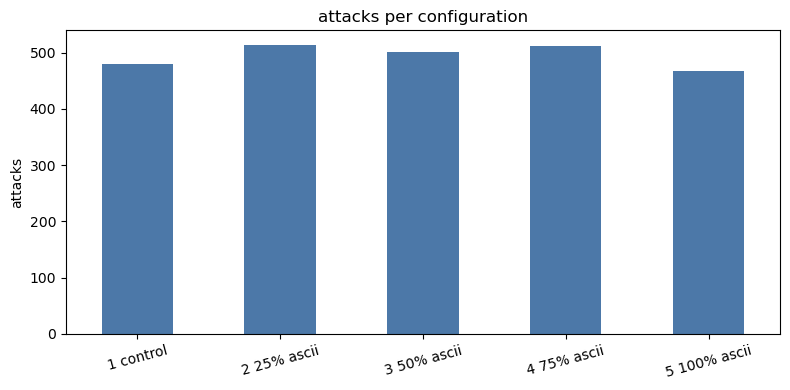

In [15]:
config_counts = df["config_label"].value_counts().reindex(ORDER)
config_share = (100 * config_counts / config_counts.sum()).round(1)
summary = pd.DataFrame({"attacks": config_counts, "percent": config_share})
display(summary)
spread = config_share.max() - config_share.min()
print(f"share spread: {spread:.1f} percentage points")
if spread <= 8:
    print("observation: the five configurations are close to an even split, so randomization is working.")
else:
    print("observation: the configurations are uneven. randomization may be off, or some honeypots were down.")

fig, ax = plt.subplots(figsize=(8, 4))
summary["attacks"].plot(kind="bar", ax=ax, color="#4c78a8")
ax.set_title("attacks per configuration")
ax.set_xlabel("")
ax.set_ylabel("attacks")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## Attack duration per configuration

All attacks. A flat top at 300 seconds means the 5 minute kick is cutting sessions off.


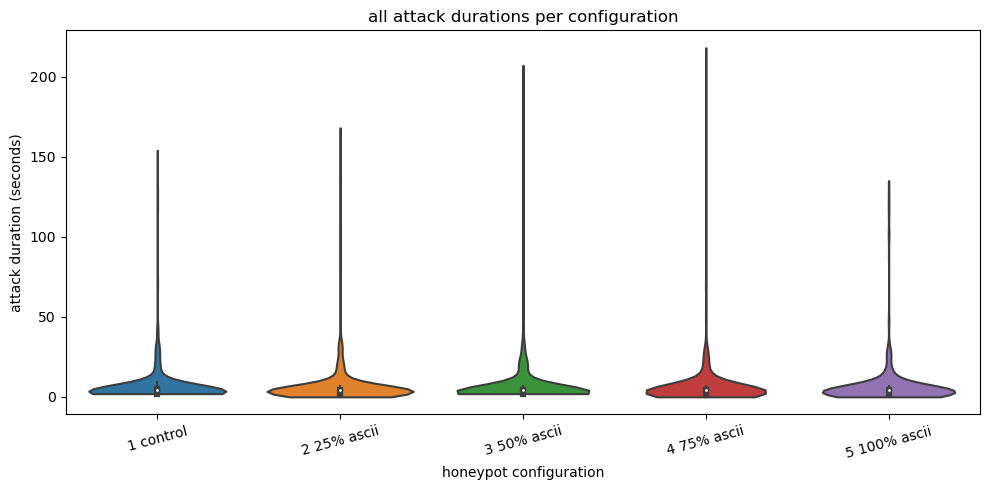

all attack durations per configuration
  1 control: n=479 median=4.0s q1=2.0s q3=5.0s max=154.0s
  2 25% ascii: n=514 median=4.0s q1=2.0s q3=4.0s max=168.0s
  3 50% ascii: n=502 median=4.0s q1=2.0s q3=4.0s max=207.0s
  4 75% ascii: n=512 median=4.0s q1=2.0s q3=4.0s max=218.0s
  5 100% ascii: n=468 median=4.0s q1=2.0s q3=4.0s max=135.0s


,configuration,n,median_s,q1_s,q3_s,max_s
0,1 control,479,4.0,2.0,5.0,154.0
1,2 25% ascii,514,4.0,2.0,4.0,168.0
2,3 50% ascii,502,4.0,2.0,4.0,207.0
3,4 75% ascii,512,4.0,2.0,4.0,218.0
4,5 100% ascii,468,4.0,2.0,4.0,135.0


median spread across configurations: 0s
observation: median durations are similar across configurations.


,timestamp,honeypot,config,attacker_ip,session_seconds,reason,commands,keystrokes,config_label,hit_time_limit
0,2026-10-28 19:52:20,hp1,3,179.43.153.2,2,attacker left,1,0,3 50% ascii,False
1,2026-10-28 19:53:42,hp1,2,179.43.153.2,2,attacker left,1,0,2 25% ascii,False
2,2026-10-28 19:55:01,hp1,3,179.43.153.2,2,attacker left,1,0,3 50% ascii,False
3,2026-10-28 19:56:21,hp1,5,179.43.153.2,2,attacker left,1,0,5 100% ascii,False
4,2026-10-28 19:57:40,hp1,4,179.43.153.2,2,attacker left,1,0,4 75% ascii,False
...,...,...,...,...,...,...,...,...,...,...
2470,2026-10-29 13:17:42,hp4,5,2.57.122.168,14,attacker left,13,1,5 100% ascii,False
2471,2026-10-29 13:17:45,hp2,4,2.57.122.168,18,attacker left,13,1,4 75% ascii,False
2472,2026-10-29 13:17:47,hp3,2,2.57.122.168,20,attacker left,15,2,2 25% ascii,False
2473,2026-10-29 13:18:47,hp3,3,2.57.122.238,2,attacker left,1,0,3 50% ascii,False


In [16]:
def show_violin(frame, title):
    plot_df = frame[frame["config_label"].isin(ORDER)].copy()
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.violinplot(
        data=plot_df,
        x="config_label",
        y="session_seconds",
        order=ORDER,
        inner="box",
        cut=0,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("honeypot configuration")
    ax.set_ylabel("attack duration (seconds)")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

    print(title)
    medians = []
    rows = []
    for label in ORDER:
        group = plot_df.loc[plot_df["config_label"] == label, "session_seconds"]
        if group.empty:
            print(f"  {label}: n=0")
            continue
        median = float(group.median())
        medians.append(median)
        row = {
            "configuration": label,
            "n": int(len(group)),
            "median_s": round(median, 1),
            "q1_s": round(float(group.quantile(0.25)), 1),
            "q3_s": round(float(group.quantile(0.75)), 1),
            "max_s": round(float(group.max()), 1),
        }
        rows.append(row)
        print(
            f"  {label}: n={row['n']} median={row['median_s']}s "
            f"q1={row['q1_s']}s q3={row['q3_s']}s max={row['max_s']}s"
        )
    display(pd.DataFrame(rows))
    if len(medians) >= 2:
        spread = max(medians) - min(medians)
        print(f"median spread across configurations: {spread:.0f}s")
        if spread <= 15:
            print("observation: median durations are similar across configurations.")
        else:
            print("observation: median duration differs by configuration. compare the printed medians.")
    return plot_df

show_violin(df, "all attack durations per configuration")


## Attack duration per configuration, excluding the 5 minute limit

Same plot after dropping sessions that reached 300 seconds. If the violins barely change, almost nobody was stopped by the time limit.


removed 0 attacks that reached the time limit
remaining attacks: 2475


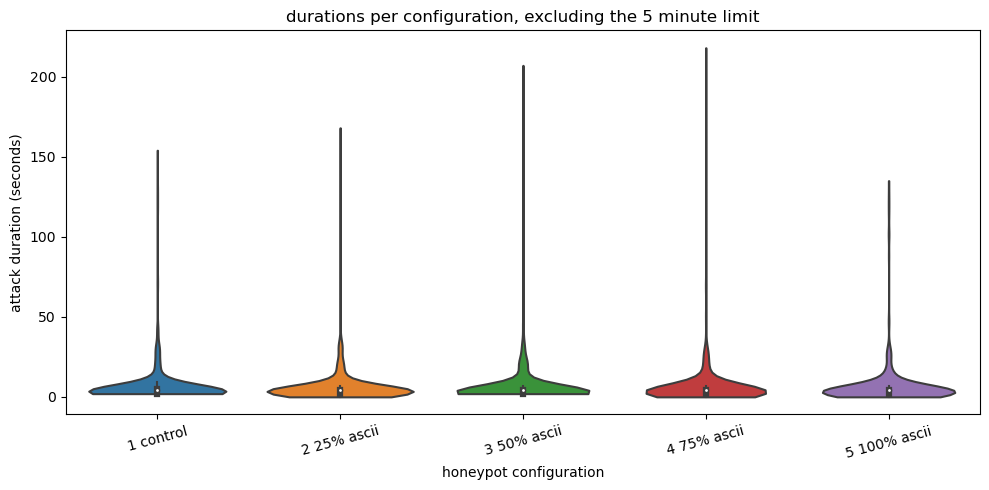

durations per configuration, excluding the 5 minute limit
  1 control: n=479 median=4.0s q1=2.0s q3=5.0s max=154.0s
  2 25% ascii: n=514 median=4.0s q1=2.0s q3=4.0s max=168.0s
  3 50% ascii: n=502 median=4.0s q1=2.0s q3=4.0s max=207.0s
  4 75% ascii: n=512 median=4.0s q1=2.0s q3=4.0s max=218.0s
  5 100% ascii: n=468 median=4.0s q1=2.0s q3=4.0s max=135.0s


,configuration,n,median_s,q1_s,q3_s,max_s
0,1 control,479,4.0,2.0,5.0,154.0
1,2 25% ascii,514,4.0,2.0,4.0,168.0
2,3 50% ascii,502,4.0,2.0,4.0,207.0
3,4 75% ascii,512,4.0,2.0,4.0,218.0
4,5 100% ascii,468,4.0,2.0,4.0,135.0


median spread across configurations: 0s
observation: median durations are similar across configurations.


,timestamp,honeypot,config,attacker_ip,session_seconds,reason,commands,keystrokes,config_label,hit_time_limit
0,2026-10-28 19:52:20,hp1,3,179.43.153.2,2,attacker left,1,0,3 50% ascii,False
1,2026-10-28 19:53:42,hp1,2,179.43.153.2,2,attacker left,1,0,2 25% ascii,False
2,2026-10-28 19:55:01,hp1,3,179.43.153.2,2,attacker left,1,0,3 50% ascii,False
3,2026-10-28 19:56:21,hp1,5,179.43.153.2,2,attacker left,1,0,5 100% ascii,False
4,2026-10-28 19:57:40,hp1,4,179.43.153.2,2,attacker left,1,0,4 75% ascii,False
...,...,...,...,...,...,...,...,...,...,...
2470,2026-10-29 13:17:42,hp4,5,2.57.122.168,14,attacker left,13,1,5 100% ascii,False
2471,2026-10-29 13:17:45,hp2,4,2.57.122.168,18,attacker left,13,1,4 75% ascii,False
2472,2026-10-29 13:17:47,hp3,2,2.57.122.168,20,attacker left,15,2,2 25% ascii,False
2473,2026-10-29 13:18:47,hp3,3,2.57.122.238,2,attacker left,1,0,3 50% ascii,False


In [17]:
kept = df[~df["hit_time_limit"]].copy()
print(f"removed {int(df['hit_time_limit'].sum())} attacks that reached the time limit")
print(f"remaining attacks: {len(kept)}")
show_violin(kept, "durations per configuration, excluding the 5 minute limit")


## First attack from each IP, per configuration

One row per IP: the earliest timestamp. The point is placed in the configuration of that first attack. Repeat visits from the same scanner no longer fill the violin.


unique ips: 32 (from 2475 attacks with an ip)


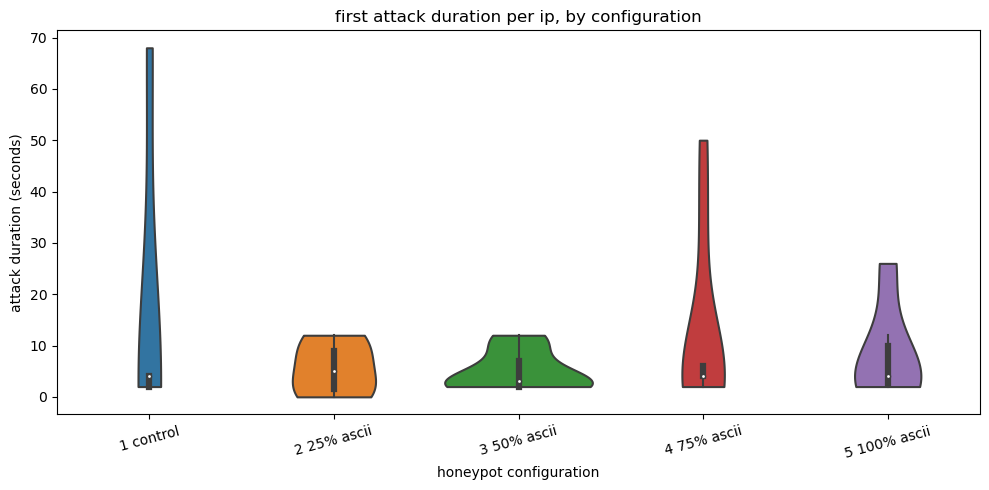

first attack duration per ip, by configuration
  1 control: n=5 median=4.0s q1=2.0s q3=4.0s max=68.0s
  2 25% ascii: n=4 median=5.0s q1=1.5s q3=9.0s max=12.0s
  3 50% ascii: n=8 median=3.0s q1=2.0s q3=7.0s max=12.0s
  4 75% ascii: n=9 median=4.0s q1=4.0s q3=6.0s max=50.0s
  5 100% ascii: n=6 median=4.0s q1=2.5s q3=10.0s max=26.0s


,configuration,n,median_s,q1_s,q3_s,max_s
0,1 control,5,4.0,2.0,4.0,68.0
1,2 25% ascii,4,5.0,1.5,9.0,12.0
2,3 50% ascii,8,3.0,2.0,7.0,12.0
3,4 75% ascii,9,4.0,4.0,6.0,50.0
4,5 100% ascii,6,4.0,2.5,10.0,26.0


median spread across configurations: 2s
observation: median durations are similar across configurations.


,timestamp,honeypot,config,attacker_ip,session_seconds,reason,commands,keystrokes,config_label,hit_time_limit
0,2026-10-28 19:52:20,hp1,3,179.43.153.2,2,attacker left,1,0,3 50% ascii,False
19,2026-10-28 20:17:06,hp2,1,162.243.72.114,2,attacker left,1,0,1 control,False
21,2026-10-28 20:18:23,hp4,5,107.170.22.5,2,attacker left,1,0,5 100% ascii,False
23,2026-10-28 20:19:21,hp4,3,162.243.2.60,2,attacker left,1,0,3 50% ascii,False
38,2026-10-28 20:29:16,hp4,3,107.170.38.102,2,attacker left,1,0,3 50% ascii,False
46,2026-10-28 20:36:19,hp4,4,179.43.153.10,4,attacker left,1,0,4 75% ascii,False
59,2026-10-28 20:44:11,hp4,2,162.243.2.239,0,attacker left,1,0,2 25% ascii,False
90,2026-10-28 21:14:16,hp1,4,107.170.19.20,3,attacker left,1,0,4 75% ascii,False
91,2026-10-28 21:14:21,hp2,3,92.118.39.50,10,attacker left,15,2,3 50% ascii,False
159,2026-10-28 21:50:29,hp4,3,128.14.232.142,12,attacker left,15,2,3 50% ascii,False


In [18]:
known = df[df["attacker_ip"].fillna("").ne("") & df["attacker_ip"].ne("unknown")].copy()
first = known.sort_values("timestamp").drop_duplicates("attacker_ip", keep="first")
print(f"unique ips: {len(first)} (from {len(known)} attacks with an ip)")
show_violin(first, "first attack duration per ip, by configuration")


## First attack from each IP, excluding the 5 minute limit

Same first-attack points. IPs whose first attack reached 300 seconds are omitted.


removed 0 first attacks that reached the time limit
remaining unique ips: 32


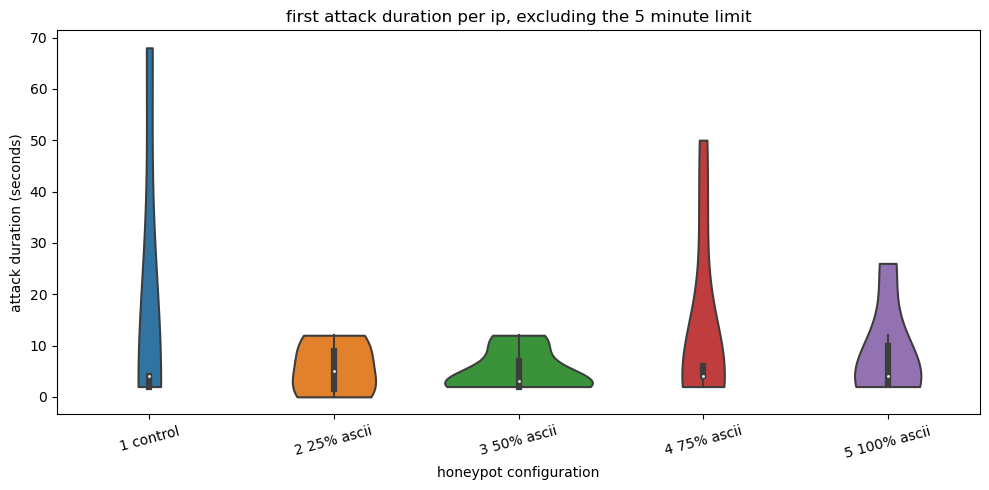

first attack duration per ip, excluding the 5 minute limit
  1 control: n=5 median=4.0s q1=2.0s q3=4.0s max=68.0s
  2 25% ascii: n=4 median=5.0s q1=1.5s q3=9.0s max=12.0s
  3 50% ascii: n=8 median=3.0s q1=2.0s q3=7.0s max=12.0s
  4 75% ascii: n=9 median=4.0s q1=4.0s q3=6.0s max=50.0s
  5 100% ascii: n=6 median=4.0s q1=2.5s q3=10.0s max=26.0s


,configuration,n,median_s,q1_s,q3_s,max_s
0,1 control,5,4.0,2.0,4.0,68.0
1,2 25% ascii,4,5.0,1.5,9.0,12.0
2,3 50% ascii,8,3.0,2.0,7.0,12.0
3,4 75% ascii,9,4.0,4.0,6.0,50.0
4,5 100% ascii,6,4.0,2.5,10.0,26.0


median spread across configurations: 2s
observation: median durations are similar across configurations.


,timestamp,honeypot,config,attacker_ip,session_seconds,reason,commands,keystrokes,config_label,hit_time_limit
0,2026-10-28 19:52:20,hp1,3,179.43.153.2,2,attacker left,1,0,3 50% ascii,False
19,2026-10-28 20:17:06,hp2,1,162.243.72.114,2,attacker left,1,0,1 control,False
21,2026-10-28 20:18:23,hp4,5,107.170.22.5,2,attacker left,1,0,5 100% ascii,False
23,2026-10-28 20:19:21,hp4,3,162.243.2.60,2,attacker left,1,0,3 50% ascii,False
38,2026-10-28 20:29:16,hp4,3,107.170.38.102,2,attacker left,1,0,3 50% ascii,False
46,2026-10-28 20:36:19,hp4,4,179.43.153.10,4,attacker left,1,0,4 75% ascii,False
59,2026-10-28 20:44:11,hp4,2,162.243.2.239,0,attacker left,1,0,2 25% ascii,False
90,2026-10-28 21:14:16,hp1,4,107.170.19.20,3,attacker left,1,0,4 75% ascii,False
91,2026-10-28 21:14:21,hp2,3,92.118.39.50,10,attacker left,15,2,3 50% ascii,False
159,2026-10-28 21:50:29,hp4,3,128.14.232.142,12,attacker left,15,2,3 50% ascii,False


In [19]:
first_kept = first[~first["hit_time_limit"]].copy()
print(f"removed {int(first['hit_time_limit'].sum())} first attacks that reached the time limit")
print(f"remaining unique ips: {len(first_kept)}")
show_violin(first_kept, "first attack duration per ip, excluding the 5 minute limit")
